# CIS 5450 Final Project: EV Energy and Thermal Monitoring
*Dee Xie, Hari Raman, Sumit Kolpe, Aditya Bajoria, Aditya Muppavarapu*

| RQ | Question | Method | Owner |
| --- | --- | --- | --- |
| Data | Load, merge and clean 98M raw sensor readings into analysis-ready data, and explore it | DuckDB (load and pivot to a 10-second grid), pandas (cleaning, gap filling, trip segmentation), EDA visuals | Sumit |
| RQ1 | Can trips be grouped into driving regimes, and does energy use differ between them? | K-Means and PCA (unsupervised) | Aditya B |
| RQ2 | Can battery temperature be predicted 5 minutes ahead? | Ridge and XGBoost (supervised) | Dee, Hari |
| RQ3 | Can the first 5 minutes of a trip predict energy use for the rest of it? | Lasso and Random Forest (supervised) | Aditya M, Sumit |

Each RQ ends with the permutation test from our proposal. RQ4 (thermal demand) and RQ5 (battery health) come later.

## Setup

In [1]:
import importlib.util
import json
import os
import shutil
import urllib.request
import zipfile
from pathlib import Path

if importlib.util.find_spec("duckdb") is None:
    %pip install -q duckdb
if importlib.util.find_spec("xgboost") is None:
    %pip install -q xgboost

In [2]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

threadpool_limits(limits=1, user_api="blas")
rng = np.random.default_rng(0)

# Part 1: Data Loading and Cleaning
We turn 98 million raw sensor readings into one row per car every 10 seconds (`tel`) and one row per trip (`trips`).

## 1.1 Download the raw data
The first run downloads the TUM dataset from Zenodo (about 620 MB) into `data/raw/`.

In [3]:
REBUILD_DATA = False
RAW_DIR = Path(os.environ.get("EV_RAW_DIR", "data/raw"))
PROCESSED_DIR = Path("data/processed")
ZENODO_URL = "https://zenodo.org/records/17532823/files/electric-vehicle-uds-dataset-public.zip?download=1"
VEHICLES = ["CUP1", "CUP2", "CUP3", "CUP4", "CUP5", "ID1", "ID2"]
NEEDED_FILES = ["value_overview.csv"] + [f"{v}.parquet" for v in VEHICLES]

In [4]:
def download_raw_data():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = RAW_DIR / "ev_dataset.zip.part"
    with tqdm(desc="Downloading", unit="B", unit_scale=True, unit_divisor=1024) as bar:
        def show_progress(blocks_done, block_size, total_size):
            done = blocks_done * block_size
            if total_size > 0:
                bar.total, done = total_size, min(done, total_size)
            bar.update(done - bar.n)

        urllib.request.urlretrieve(ZENODO_URL, zip_path, reporthook=show_progress)

    with zipfile.ZipFile(zip_path) as z:
        files = [name for name in z.namelist() if Path(name).name in NEEDED_FILES and not name.startswith("__MACOSX")]
        for name in tqdm(files, desc="Extracting"):
            with z.open(name) as src, open(RAW_DIR / Path(name).name, "wb") as dst:
                shutil.copyfileobj(src, dst)
    zip_path.unlink()

In [5]:
if not all((RAW_DIR / f).exists() for f in NEEDED_FILES):
    download_raw_data()

missing_files = [f for f in NEEDED_FILES if not (RAW_DIR / f).exists()]
assert not missing_files, f"Download incomplete, missing: {missing_files}"
sorted(p.name for p in RAW_DIR.iterdir())

['CUP1.parquet',
 'CUP2.parquet',
 'CUP3.parquet',
 'CUP4.parquet',
 'CUP5.parquet',
 'ID1.parquet',
 'ID2.parquet',
 'value_overview.csv']

## 1.2 Signals we use
We keep the 15 sensors that contain data and give them readable names.

In [6]:
SIGNALS = {
    4: "speed",
    900: "soc",
    1200: "hv_voltage",
    56: "hv_aux_power",
    15: "ambient_temp",
    43: "interior_temp",
    1209: "bat_temp",
    1208: "bat_temp_min",
    1272: "bat_inlet_temp",
    1273: "bat_outlet_temp",
    1269: "coolant_temp",
    961: "motor_temp",
    1265: "rotor_temp",
    1205: "ptc_current",
    1207: "ptc_voltage",
}
SIGNAL_COLUMNS = list(SIGNALS.values())

overview = pd.read_csv(RAW_DIR / "value_overview.csv").drop_duplicates("value_id").set_index("value_id")
signal_table = overview.loc[list(SIGNALS), ["name_en", "unit"]]
signal_table.insert(0, "column", SIGNAL_COLUMNS)
signal_table

,column,name_en,unit
value_id,,,
4,speed,vehicle speed,km/h
900,soc,SOC,%
1200,hv_voltage,pack voltage,V
56,hv_aux_power,Power HV Aux,W
15,ambient_temp,Ambient air temperature,°C
43,interior_temp,Interior Temperature,°C
1209,bat_temp,HV Battery Temp max.,°C
1208,bat_temp_min,HV Battery Temp min.,°C
1272,bat_inlet_temp,Battery pack inlet temp,°C


## 1.3 The raw data
One row per sensor reading. Readings with impossible timestamps (e.g. year 2087) are dropped.

In [7]:
RAW = f"read_parquet({[(RAW_DIR / f'{v}.parquet').as_posix() for v in VEHICLES]})"
VALID_TIME = "CAST(time AS TIMESTAMP) BETWEEN TIMESTAMP '2020-01-01' AND TIMESTAMP '2024-12-31'"

display(duckdb.sql(f"SELECT * FROM {RAW} LIMIT 5").df())

raw_summary = duckdb.sql(f"""
    SELECT vehicle_id,
           COUNT(*) AS readings,
           COUNT(*) FILTER (WHERE NOT ({VALID_TIME})) AS impossible_timestamps,
           MIN(time) FILTER (WHERE {VALID_TIME})::DATE AS first_day,
           MAX(time) FILTER (WHERE {VALID_TIME})::DATE AS last_day
    FROM {RAW}
    GROUP BY vehicle_id
    ORDER BY vehicle_id
""").df()
print(f"Raw readings: {raw_summary['readings'].sum():,}")
raw_summary

,vehicle_id,time,value_id,value
0,CUP1,2087-03-07 15:45:43.011,4,4.68
1,CUP1,2087-03-07 15:45:43.163,1200,402.50
2,CUP1,2087-03-07 15:45:43.211,1200,402.50
3,CUP1,2087-03-07 15:45:43.229,4,4.65
4,CUP1,2087-03-07 15:45:43.374,1200,402.50


Raw readings: 98,061,214


,vehicle_id,readings,impossible_timestamps,first_day,last_day
0,CUP1,8659492,812,2022-11-15,2023-04-24
1,CUP2,3743488,0,2022-11-21,2023-05-04
2,CUP3,986864,0,2022-11-17,2023-04-23
3,CUP4,4943471,0,2022-11-15,2023-04-14
4,CUP5,3305981,0,2022-11-10,2023-04-23
5,ID1,40401700,0,2021-02-01,2023-06-13
6,ID2,36020218,0,2021-07-26,2023-10-10


## 1.4 Pivot into 10-second rows
DuckDB averages each sensor into one row per car every 10 seconds.

In [8]:
def load_10s_grid():
    columns = ",\n".join(f"AVG(value) FILTER (WHERE value_id = {vid}) AS {name}" for vid, name in SIGNALS.items())
    return duckdb.sql(f"""
        SELECT vehicle_id,
               time_bucket(INTERVAL '10 seconds', CAST(time AS TIMESTAMP)) AS ts,
               {columns}
        FROM {RAW}
        WHERE {VALID_TIME}
          AND value_id IN ({", ".join(str(v) for v in SIGNALS)})
          AND value IS NOT NULL
        GROUP BY 1, 2
        ORDER BY 1, 2
    """).df()

## 1.5 Remove invalid values
Values outside physical limits, and zeros that are logger placeholders, are set to missing.

In [9]:
VALID_RANGES = {
    "speed": (0, 200),
    "soc": (0, 100),
    "hv_voltage": (200, 500),
    "hv_aux_power": (-20000, 20000),
    "ambient_temp": (-40, 60),
    "interior_temp": (-40, 80),
    "bat_temp": (-40, 80),
    "bat_temp_min": (-40, 80),
    "bat_inlet_temp": (-40, 80),
    "bat_outlet_temp": (-40, 80),
    "coolant_temp": (-40, 120),
    "motor_temp": (-40, 200),
    "rotor_temp": (-40, 250),
}
ZERO_IS_MISSING = ["soc", "hv_voltage", "bat_temp", "bat_temp_min", "bat_inlet_temp", "bat_outlet_temp"]

In [10]:
def remove_invalid_values(df):
    df = df.copy()
    report = []
    for col, (low, high) in VALID_RANGES.items():
        n_values = df[col].notna().sum()
        zeros = (df[col] == 0) if col in ZERO_IS_MISSING else pd.Series(False, index=df.index)
        df.loc[zeros, col] = np.nan
        out_of_range = df[col].notna() & ~df[col].between(low, high)
        df.loc[out_of_range, col] = np.nan
        report.append({"column": col, "values": n_values, "placeholder_zeros": zeros.sum(),
                       "out_of_range": out_of_range.sum()})
    return df, pd.DataFrame(report)

## 1.6 Remove spikes
A temperature reading far from the median of its neighbours is a sensor glitch and is set to missing.

In [11]:
SPIKE_LIMITS = {"bat_inlet_temp": 4, "bat_outlet_temp": 4, "coolant_temp": 4, "motor_temp": 6, "rotor_temp": 8,
                "ambient_temp": 4}


def remove_spikes(df):
    df = df.sort_values(["vehicle_id", "ts"]).reset_index(drop=True)
    removed = {}
    for col, limit in SPIKE_LIMITS.items():
        median = df.groupby("vehicle_id")[col].transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
        spikes = (df[col] - median).abs() > limit
        removed[col] = int(spikes.sum())
        df.loc[spikes, col] = np.nan
    return df, removed

## 1.7 Fill short gaps
Battery temperature is interpolated across gaps of up to 10 minutes, other sensors are carried forward for up to 60 seconds, and speed is never filled.

In [12]:
INTERPOLATED = ["bat_temp", "bat_temp_min"]


def interpolate_short_gaps(df, col, max_gap_s=600):
    filled = []
    for _, g in df.groupby("vehicle_id"):
        s = g.set_index("ts")[col]
        seen = s.index.to_series().where(s.notna())
        gap = (seen.bfill() - seen.ffill()).dt.total_seconds()
        filled.append(s.interpolate(method="time", limit_area="inside").where(gap <= max_gap_s).to_numpy())
    return np.concatenate(filled)

In [13]:
def forward_fill_short_gaps(df, col, max_gap_s=60):
    last_seen = df["ts"].where(df[col].notna()).groupby(df["vehicle_id"]).ffill()
    filled = df[col].groupby(df["vehicle_id"]).ffill()
    return filled.where((df["ts"] - last_seen).dt.total_seconds() <= max_gap_s)

In [14]:
def fill_missing(df):
    df = df.copy()
    for col in INTERPOLATED:
        df[f"{col}_observed"] = df[col].notna()
        df[col] = interpolate_short_gaps(df, col)
    for col in SIGNAL_COLUMNS:
        if col not in ["speed", *INTERPOLATED]:
            df[col] = forward_fill_short_gaps(df, col)
    return df

## 1.8 Distance and acceleration
Distance is speed × 10 seconds, and acceleration is the change in speed between rows.

In [15]:
def add_motion(df):
    df = df.copy()
    df["dt_s"] = df.groupby("vehicle_id")["ts"].diff().dt.total_seconds()
    df["dist_km"] = df["speed"].fillna(0) * 10 / 3600
    speed_change = df.groupby("vehicle_id")["speed"].diff() / 3.6
    df["accel_ms2"] = (speed_change / df["dt_s"]).where(df["dt_s"] <= 15)
    return df

## 1.9 Split into trips
A trip is a run of rows above 2 km/h, stops under 5 minutes stay inside it, and trips under 2 minutes or 0.5 km are dropped.

In [16]:
def split_trips(df, moving_kmh=2, max_stop_s=300, min_s=120, min_km=0.5):
    df = df.copy()
    df["trip_id"] = None
    for vehicle, g in df.groupby("vehicle_id"):
        moving_ts = g.loc[g["speed"] > moving_kmh, "ts"]
        trip_no = moving_ts.diff().dt.total_seconds().gt(max_stop_s).cumsum()
        starts = moving_ts.groupby(trip_no).min().to_numpy()
        ends = moving_ts.groupby(trip_no).max().to_numpy()

        idx = np.searchsorted(starts, g["ts"].to_numpy(), side="right") - 1
        in_trip = (idx >= 0) & (g["ts"].to_numpy() <= ends[np.clip(idx, 0, None)])
        raw_trip = pd.Series(np.where(in_trip, idx, -1), index=g.index)

        duration = (ends - starts) / np.timedelta64(1, "s") + 10
        distance = g["dist_km"].groupby(raw_trip).sum()
        keep = [k for k in range(len(starts)) if duration[k] >= min_s and distance.get(k, 0) >= min_km]
        names = {k: f"{vehicle}_{i + 1:04d}" for i, k in enumerate(keep)}
        df.loc[g.index, "trip_id"] = raw_trip.map(names)

    in_trip = df["trip_id"].notna()
    grouped = df[in_trip].groupby("trip_id")
    df.loc[in_trip, "trip_elapsed_s"] = (df.loc[in_trip, "ts"] - grouped["ts"].transform("min")).dt.total_seconds()
    df.loc[in_trip, "trip_dist_km"] = grouped["dist_km"].cumsum()
    df["state"] = np.where(in_trip, "driving", "parked")
    return df

## 1.10 Trip table
One row per trip. Energy use is the battery % used per 100 km (`soc_per_100km`).

In [17]:
def build_trip_table(tel):
    t = tel[tel["trip_id"].notna()].copy()
    t["stopped"] = t["speed"] <= 2
    g = t.groupby("trip_id")

    trips = pd.DataFrame({
        "vehicle_id": g["vehicle_id"].first(),
        "start_ts": g["ts"].min(),
        "end_ts": g["ts"].max(),
        "n_rows": g.size(),
        "distance_km": g["dist_km"].sum(),
        "speed_mean_moving": t[~t["stopped"]].groupby("trip_id")["speed"].mean(),
        "speed_mean": g["speed"].mean(),
        "speed_max": g["speed"].max(),
        "speed_std": g["speed"].std(),
        "stop_fraction": g["stopped"].mean(),
        "accel_abs_mean": g["accel_ms2"].apply(lambda s: s.abs().mean()),
        "accel_p95": g["accel_ms2"].quantile(0.95),
        "decel_p05": g["accel_ms2"].quantile(0.05),
        "soc_start": g["soc"].first(),
        "soc_end": g["soc"].last(),
    })
    trips["duration_min"] = (trips["end_ts"] - trips["start_ts"]).dt.total_seconds() / 60 + 10 / 60
    trips["soc_used"] = trips["soc_start"] - trips["soc_end"]
    trips["soc_per_100km"] = 100 * trips["soc_used"] / trips["distance_km"]
    for col in ["bat_temp", "bat_outlet_temp"]:
        trips[f"{col}_start"] = g[col].first()
        trips[f"{col}_end"] = g[col].last()
        trips[f"{col}_max"] = g[col].max()
        trips[f"{col}_rise"] = trips[f"{col}_end"] - trips[f"{col}_start"]
    for col in ["ambient_temp", "hv_voltage", "hv_aux_power", "coolant_temp", "motor_temp", "interior_temp",
                "bat_inlet_temp"]:
        trips[f"{col}_mean"] = g[col].mean()
    trips["start_hour"] = trips["start_ts"].dt.hour
    trips["start_month"] = trips["start_ts"].dt.month
    trips["weekday"] = trips["start_ts"].dt.dayofweek

    believable = (trips["soc_used"] > 0) & trips["soc_per_100km"].between(5, 100)
    trips["energy_valid_5km"] = believable & (trips["distance_km"] >= 5)
    trips["energy_valid_20km"] = believable & (trips["distance_km"] >= 20)
    return trips.reset_index()

## 1.11 Run the pipeline
The result is saved to `data/processed/`, so later runs load it in seconds.

In [18]:
OUTPUTS = ["telemetry_10s.parquet", "trips.parquet", "trips.csv", "data_quality_report.csv", "pipeline_params.json"]

if REBUILD_DATA or not all((PROCESSED_DIR / f).exists() for f in OUTPUTS):
    tel = load_10s_grid()
    missing_raw = tel[SIGNAL_COLUMNS].isna().mean()
    tel, invalid_report = remove_invalid_values(tel)
    tel, spikes_removed = remove_spikes(tel)
    tel = fill_missing(tel)
    missing_after = tel[SIGNAL_COLUMNS].isna().mean()
    tel = add_motion(tel)
    tel = split_trips(tel)
    trips = build_trip_table(tel)

    missing = pd.DataFrame({"missing_raw_pct": missing_raw, "missing_after_fill_pct": missing_after}).mul(100).round(2)
    quality = missing.rename_axis("column").reset_index().merge(invalid_report, on="column", how="left")
    params = {
        "raw_readings": int(raw_summary["readings"].sum()),
        "impossible_timestamps": int(raw_summary["impossible_timestamps"].sum()),
        "rows_10s": len(tel),
        "trips": len(trips),
        "spikes_removed": spikes_removed,
    }

    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    tel.to_parquet(PROCESSED_DIR / "telemetry_10s.parquet", index=False)
    trips.to_parquet(PROCESSED_DIR / "trips.parquet", index=False)
    trips.to_csv(PROCESSED_DIR / "trips.csv", index=False)
    quality.to_csv(PROCESSED_DIR / "data_quality_report.csv", index=False)
    (PROCESSED_DIR / "pipeline_params.json").write_text(json.dumps(params, indent=2))

In [19]:
tel = pd.read_parquet(PROCESSED_DIR / "telemetry_10s.parquet")
trips = pd.read_parquet(PROCESSED_DIR / "trips.parquet")
quality = pd.read_csv(PROCESSED_DIR / "data_quality_report.csv")
params = json.loads((PROCESSED_DIR / "pipeline_params.json").read_text())

print(f"10-second rows: {len(tel):,} ({(tel['state'] == 'driving').sum():,} while driving)")
print(f"Trips: {len(trips):,}")

10-second rows: 911,145 (290,380 while driving)
Trips: 2,389


## 1.12 Checks

In [20]:
trip_rows = tel[tel["trip_id"].notna()]
checks = {
    "one row per vehicle per 10 s": not tel.duplicated(["vehicle_id", "ts"]).any(),
    "all timestamps between 2020 and 2024": tel["ts"].between("2020-01-01", "2024-12-31").all(),
    "every trip has a moving row": (trip_rows.groupby("trip_id")["speed"].max() > 2).all(),
    "every trip belongs to one vehicle": (trip_rows.groupby("trip_id")["vehicle_id"].nunique() == 1).all(),
    "trip table matches the telemetry": set(trips["trip_id"]) == set(trip_rows["trip_id"]),
    "all values inside the valid ranges": all(tel[c].dropna().between(*r).all() for c, r in VALID_RANGES.items()),
}
assert all(checks.values()), checks
pd.Series(checks, name="passed")

one row per vehicle per 10 s            True
all timestamps between 2020 and 2024    True
every trip has a moving row             True
every trip belongs to one vehicle       True
trip table matches the telemetry        True
all values inside the valid ranges      True
Name: passed, dtype: bool

In [21]:
duckdb.sql("""
    SELECT vehicle_id,
           COUNT(*) AS trips,
           ROUND(SUM(distance_km)) AS km,
           MIN(start_ts)::DATE AS first_trip,
           MAX(start_ts)::DATE AS last_trip
    FROM trips
    GROUP BY vehicle_id
    ORDER BY trips DESC
""").df()

,vehicle_id,trips,km,first_trip,last_trip
0,ID2,836,18089.0,2021-07-26,2023-10-10
1,ID1,511,15448.0,2021-02-02,2023-06-07
2,CUP1,395,4049.0,2022-11-15,2023-04-24
3,CUP4,226,2333.0,2022-11-23,2023-04-06
4,CUP5,188,1343.0,2022-11-10,2023-04-23
5,CUP2,187,1859.0,2022-11-21,2023-04-21
6,CUP3,46,541.0,2022-11-21,2023-04-06


## 1.13 Trips used for the energy analysis
Battery % is logged in 0.4% steps, so energy use is only reliable for trips of at least 5 km.

In [22]:
energy = trips[trips["energy_valid_5km"] & trips["ambient_temp_mean"].notna()].copy()
driving = tel[tel["state"] == "driving"]

display(pd.Series({
    "All trips": len(trips),
    "At least 5 km": (trips["distance_km"] >= 5).sum(),
    "... and believable energy use": trips["energy_valid_5km"].sum(),
    "... and an outside temperature reading": len(energy),
}, name="trips"))

print("Raw energy range:", round(trips["soc_per_100km"].min(), 1), "to", round(trips["soc_per_100km"].max(), 1),
      "SOC % per 100 km")
print("Driving rows with a speed reading:", round(driving["speed"].notna().mean() * 100, 1), "%")
print("Driving rows missing pack temperature (after interpolation):", round(driving["bat_temp"].isna().mean() * 100), "%")

All trips                                 2389
At least 5 km                             1388
... and believable energy use             1374
... and an outside temperature reading    1326
Name: trips, dtype: int64

Raw energy range: -111.6 to 331.1 SOC % per 100 km
Driving rows with a speed reading: 99.9 %
Driving rows missing pack temperature (after interpolation): 57 %


# Part 2: Exploratory Data Analysis

## 2.1 When each car was logged

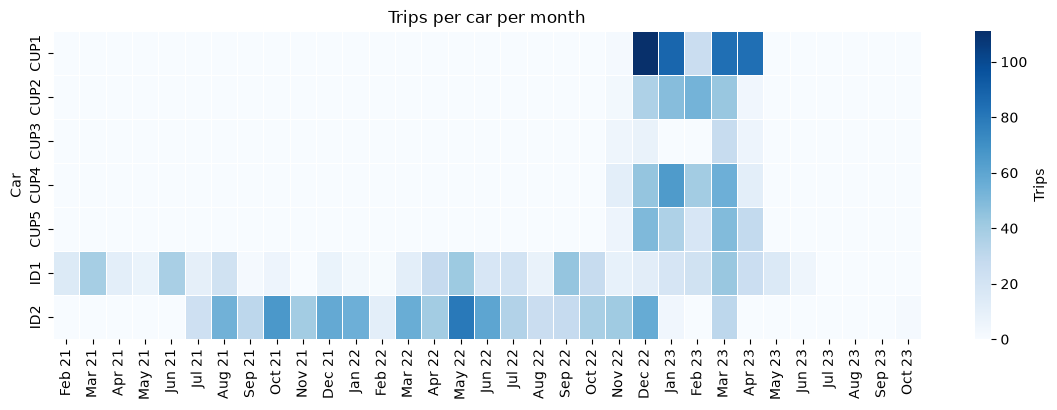

In [23]:
trip_month = trips["start_ts"].dt.to_period("M")
all_months = pd.period_range(trip_month.min(), trip_month.max(), freq="M")
coverage = pd.crosstab(trips["vehicle_id"], trip_month).reindex(columns=all_months, fill_value=0)
coverage.columns = coverage.columns.strftime("%b %y")

plt.figure(figsize=(14, 4))
sns.heatmap(coverage, cmap="Blues", linewidths=0.5, linecolor="white", cbar_kws={"label": "Trips"})
plt.title("Trips per car per month")
plt.xlabel("")
plt.ylabel("Car")
plt.show()

The CUPRAs were only logged from November 2022 to April 2023, so car and season are mixed up. This is why the tests shuffle data within each car.

## 2.2 Energy use vs outside temperature

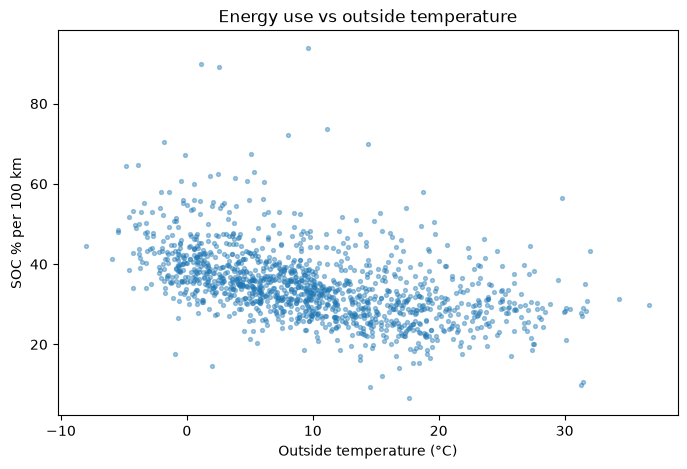

Spearman (temperature): -0.56
Spearman (mean speed): -0.04


In [24]:
plt.figure(figsize=(8, 5))
plt.scatter(energy["ambient_temp_mean"], energy["soc_per_100km"], s=8, alpha=0.4)
plt.title("Energy use vs outside temperature")
plt.xlabel("Outside temperature (°C)")
plt.ylabel("SOC % per 100 km")
plt.show()

print("Spearman (temperature):", round(spearmanr(energy["ambient_temp_mean"], energy["soc_per_100km"]).statistic, 2))
print("Spearman (mean speed):", round(spearmanr(energy["speed_mean_moving"], energy["soc_per_100km"]).statistic, 2))

Colder trips use clearly more energy, while mean speed on its own barely matters.

## 2.3 Correlation between the sensor signals
Computed on the 10-second rows recorded while driving.

In [25]:
signal_labels = {
    "speed": "Speed",
    "soc": "Battery %",
    "hv_voltage": "Battery voltage",
    "hv_aux_power": "Heater/AC power",
    "ambient_temp": "Outside temp",
    "bat_temp": "Battery temp (max)",
    "bat_temp_min": "Battery temp (min)",
    "bat_inlet_temp": "Battery inlet temp",
    "bat_outlet_temp": "Battery outlet temp",
    "coolant_temp": "Inverter coolant temp",
    "motor_temp": "Motor stator temp",
    "rotor_temp": "Motor rotor temp",
}

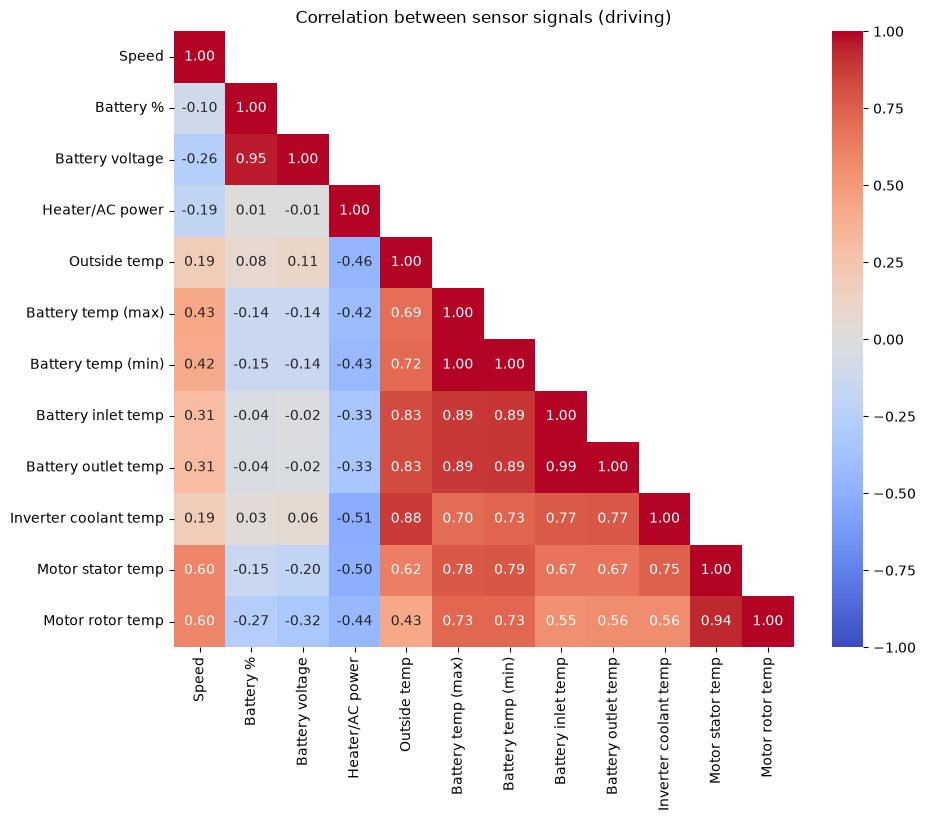

In [26]:
signal_corr = driving[list(signal_labels)].rename(columns=signal_labels).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(signal_corr, mask=np.triu(np.ones_like(signal_corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between sensor signals (driving)")
plt.show()

The temperature signals move together strongly (0.6 to 0.99), and battery % and voltage are almost the same signal (0.95). Heater/AC power rises as the outside temperature falls (-0.46), and speed is most linked to motor temperature (0.60).

## 2.4 Battery temperature readings

In [27]:
observed_share = driving.groupby("vehicle_id")["bat_temp_observed"].mean().mul(100).sort_values()

real = tel.loc[tel["trip_id"].notna() & tel["bat_temp_observed"], ["trip_id", "ts", "bat_temp"]]
later = real.rename(columns={"ts": "ts_later", "bat_temp": "bat_temp_later"}).sort_values("ts_later")
pairs = pd.merge_asof(real.assign(ts_later=real["ts"] + pd.Timedelta(minutes=5)).sort_values("ts_later"), later,
                      on="ts_later", by="trip_id", direction="nearest", tolerance=pd.Timedelta(seconds=20))
change_5min = (pairs["bat_temp_later"] - pairs["bat_temp"]).dropna()

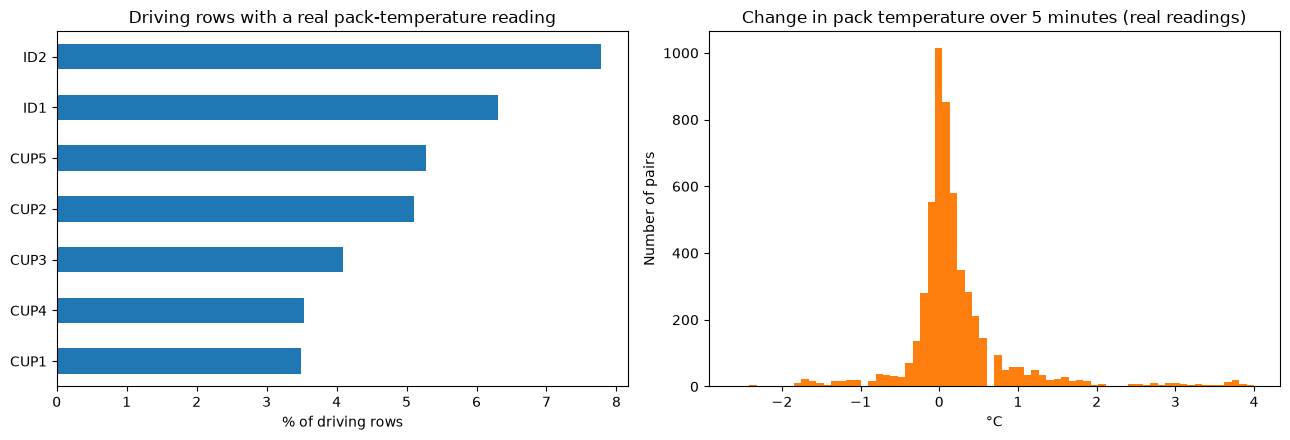

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
observed_share.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Driving rows with a real pack-temperature reading")
axes[0].set_xlabel("% of driving rows")
axes[0].set_ylabel("")
axes[1].hist(change_5min.clip(-3, 4), bins=70, color="tab:orange")
axes[1].set_title("Change in pack temperature over 5 minutes (real readings)")
axes[1].set_xlabel("°C")
axes[1].set_ylabel("Number of pairs")
plt.tight_layout()
plt.show()

In [29]:
print("Real readings in driving rows:", round(driving["bat_temp_observed"].mean() * 100, 1), "%")
print("5-minute pairs:", len(change_5min))
print("Share of 5-minute changes within ±0.5 °C:", round((change_5min.abs() <= 0.5).mean() * 100, 1), "%")
print("95th percentile of the 5-minute rise:", round(change_5min.quantile(0.95), 2), "°C")

Real readings in driving rows: 6.1 %
5-minute pairs: 5401
Share of 5-minute changes within ±0.5 °C: 80.6 %
95th percentile of the 5-minute rise: 1.3 °C


Only about 6% of driving rows have a real battery temperature reading, and it changes slowly. RQ2 therefore uses only real readings.

# Part 3: RQ1 - Driving Regimes (Unsupervised Learning) - Aditya B
Can trips be grouped into driving regimes, and does energy use differ between them?

## 3.1 Features
Seven features describe how each trip was driven. Distance and max speed are left out because they almost duplicate duration and speed variation (r = 0.93). Duration is log-transformed because it is skewed, and all features are scaled.

In [30]:
cluster_features = ["speed_mean_moving", "speed_std", "stop_fraction",
                    "accel_abs_mean", "accel_p95", "decel_p05", "duration_min"]

X = trips[cluster_features].copy()
X["duration_min"] = np.log1p(X["duration_min"])
X_scaled = StandardScaler().fit_transform(X)

## 3.2 K-Means
We try k = 2 to 8 and compare inertia and the silhouette score.

In [31]:
k_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X_scaled)
    k_results.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X_scaled, model.labels_)})

k_results = pd.DataFrame(k_results).set_index("k")
k_results.round(3)

,inertia,silhouette
k,,
2,11584.536,0.313
3,8987.301,0.265
4,7547.084,0.274
5,6591.489,0.258
6,6062.698,0.236
7,5630.912,0.229
8,5224.370,0.213


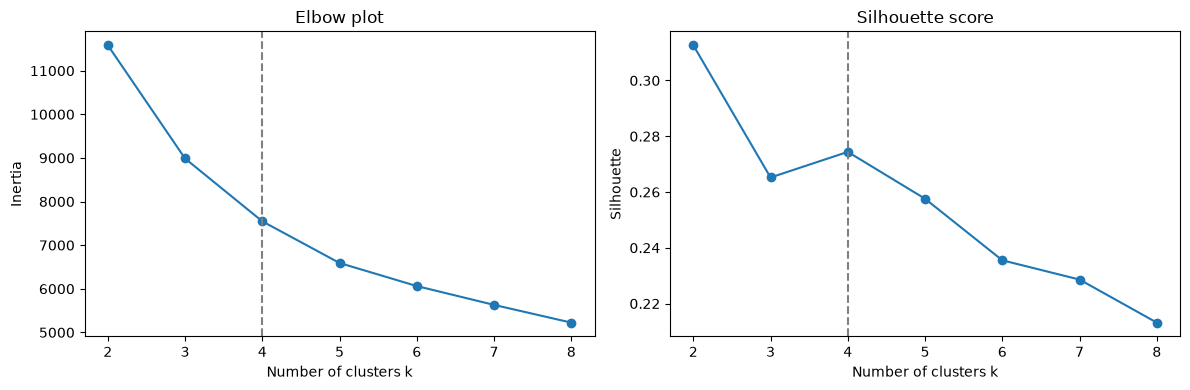

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_results.index, k_results["inertia"], marker="o")
axes[0].set_title("Elbow plot")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_results.index, k_results["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette")

for ax in axes:
    ax.axvline(4, color="gray", linestyle="--")
plt.tight_layout()
plt.show()

Inertia drops quickly up to k = 4, and the silhouette score has a local peak there. k = 2 scores higher but only separates short and long trips, so we use k = 4.

In [33]:
kmeans = KMeans(n_clusters=4, n_init=50, random_state=0).fit(X_scaled)

regime_names = ["Short urban", "Dynamic urban", "Mixed suburban", "Highway"]
cluster_speed = trips.groupby(kmeans.labels_)["speed_mean_moving"].median().sort_values()
trips["regime"] = pd.Categorical(pd.Series(kmeans.labels_).map(dict(zip(cluster_speed.index, regime_names))),
                                 categories=regime_names)

baseline_labels = pd.cut(trips["speed_mean_moving"], bins=[0, 30, 60, np.inf], labels=False)
print("Silhouette, K-Means (k = 4):", round(silhouette_score(X_scaled, kmeans.labels_), 3))
print("Silhouette, speed bins (baseline):", round(silhouette_score(X_scaled, baseline_labels), 3))
trips["regime"].value_counts().sort_index()

Silhouette, K-Means (k = 4): 0.274
Silhouette, speed bins (baseline): 0.134


regime
Short urban       792
Dynamic urban     782
Mixed suburban    612
Highway           203
Name: count, dtype: int64

K-Means separates trips twice as well as splitting them by speed alone (silhouette 0.27 vs 0.13).

In [34]:
feature_labels = {
    "speed_mean_moving": "Mean speed",
    "speed_std": "Speed variation",
    "stop_fraction": "Time stopped",
    "accel_abs_mean": "Mean |accel|",
    "accel_p95": "Hard accel",
    "decel_p05": "Hard braking",
    "duration_min": "Duration",
}

In [35]:
profile = trips.groupby("regime", observed=True).agg(
    trips=("trip_id", "count"),
    mean_speed_kmh=("speed_mean_moving", "median"),
    speed_variation_kmh=("speed_std", "median"),
    time_stopped_pct=("stop_fraction", "median"),
    hard_accel_ms2=("accel_p95", "median"),
    hard_braking_ms2=("decel_p05", "median"),
    duration_min=("duration_min", "median"),
)
profile["time_stopped_pct"] *= 100
profile["hard_braking_ms2"] *= -1
profile.round(1)

,trips,mean_speed_kmh,speed_variation_kmh,time_stopped_pct,hard_accel_ms2,hard_braking_ms2,duration_min
regime,,,,,,,
Short urban,792,24.2,15.2,16.3,0.5,0.5,8.0
Dynamic urban,782,32.0,19.8,16.7,0.7,0.7,12.3
Mixed suburban,612,56.5,36.2,8.9,0.6,0.6,23.1
Highway,203,95.4,35.1,1.6,0.3,0.3,70.5


The table shows the median trip in each regime. Highway trips are long and fast with almost no stopping, while dynamic urban trips have the hardest accelerating and braking.

## 3.3 PCA
PCA reduces the seven features to two components, so we can see the regimes and what separates them.

In [36]:
pca = PCA(n_components=2).fit(X_scaled)
pcs = pca.transform(X_scaled)
print("Variance explained:", pca.explained_variance_ratio_.round(2), "| total:", round(pca.explained_variance_ratio_.sum(), 2))

loadings = pd.DataFrame(pca.components_.T, index=[feature_labels[f] for f in cluster_features], columns=["PC1", "PC2"])
loadings.loc["Hard braking"] = -loadings.loc["Hard braking"]
loadings.round(2)

Variance explained: [0.45 0.29] | total: 0.74


,PC1,PC2
Mean speed,-0.42,0.40
Speed variation,-0.31,0.50
Time stopped,0.24,-0.20
Mean |accel|,0.47,0.33
Hard accel,0.40,0.41
Hard braking,0.39,0.42
Duration,-0.37,0.31


PC1 and PC2 explain 74% of the variation. PC1 is high for stop-and-go trips with a lot of accelerating and braking, and PC2 is high for fast trips with large speed changes.

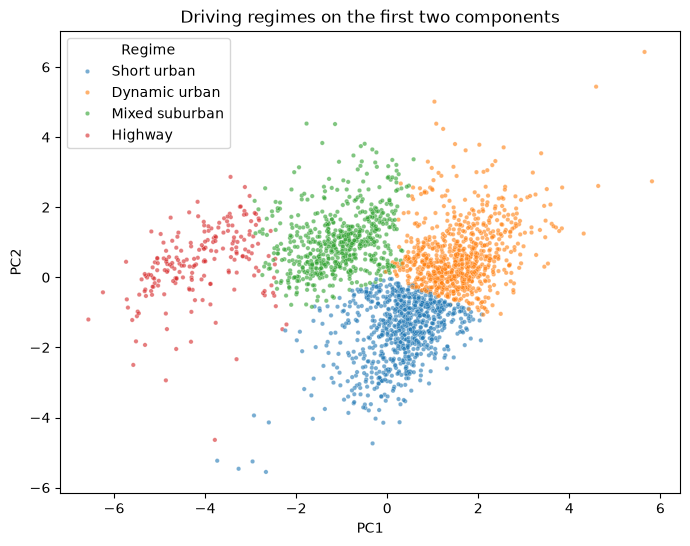

In [37]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=trips["regime"], s=10, alpha=0.6)
plt.title("Driving regimes on the first two components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Regime")
plt.show()

The regimes form clear areas but touch at the edges, so driving style is more of a spectrum than four separate groups.

## 3.4 Hypothesis test
**H0:** energy use does not depend on the driving regime.
**Test:** shuffle regime labels between trips of the same car 10,000 times. The statistic is the spread (SD) of mean energy use across regimes.

In [38]:
def shuffle_within(values, groups):
    shuffled = values.copy()
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        shuffled[idx] = rng.permutation(values[idx])
    return shuffled

In [39]:
def regime_permutation_test(df, value_col, n_perm=10_000):
    labels = df["regime"].cat.codes.to_numpy()
    values = df[value_col].to_numpy()
    vehicles = df["vehicle_id"].to_numpy()
    spread = lambda lab: np.std([values[lab == g].mean() for g in np.unique(lab)])

    observed = spread(labels)
    null = np.array([spread(shuffle_within(labels, vehicles)) for _ in range(n_perm)])
    return observed, (np.sum(null >= observed) + 1) / (n_perm + 1)

### Temperature adjustment: current methodology and interpretation

Regimes occur under heterogeneous ambient conditions; in this sample, highway trips average 13.12 degrees C, while short urban trips average 8.32 degrees C. Ambient temperature is negatively associated with SOC depletion per 100 km, so the raw regime means combine differences in driving conditions with differences associated with temperature.

**Adjustment.** On the eligible energy-analysis trips, we fit one pooled linear regression with `np.polyfit`: predicted consumption = intercept + slope * mean ambient temperature. For each trip, `soc_adjusted` is observed consumption minus this prediction. It is a residual, measured in SOC percentage points per 100 km, not an estimate of consumption at a particular reference temperature. Positive residuals mean higher consumption than the temperature-only model predicts; negative residuals mean lower consumption.

**Permutation procedure.** We calculate the standard deviation of the four regime means, first for raw consumption and then for residual consumption. For each test, we shuffle regime labels among trips within the same vehicle 10,000 times, keeping each trip's outcome fixed and preserving vehicle-specific regime counts. The upper-tail p-value is `(1 + number of shuffled statistics at least as large as observed) / 10001`. Each regime mean receives equal weight in the statistic.

**Why adjustment can reveal a difference.** Warmer highway trips may have a temperature-related efficiency advantage that offsets higher consumption associated with their driving conditions. For example, the observed short-urban and highway means are similar (35.89 and 35.37), but the temperature-only predictions are 35.58 and 33.03. Their residual means are therefore +0.31 and +2.34. The warmer highway trips use less than short-urban trips in absolute terms, yet more than this temperature-only model would predict. This is a possible masking pattern, not proof of its physical cause. Adjustment can also change residual variability and the permutation null distribution; it does not always reduce a p-value.

**Limitations.** This is an exploratory linear residual adjustment, not a causal estimate or a guaranteed exact test conditional on temperature. The model assumes a common linear temperature association; vehicle-specific responses, nonlinear effects, season, route, load and dependence between trips may remain. Because regime and temperature are associated, shuffling regime labels after residualizing only the outcome does not automatically satisfy conditional exchangeability. Within-vehicle shuffling preserves vehicle membership but does not by itself resolve these issues. Confirmatory analysis needs a justified joint vehicle/temperature/regime model and dependence-aware inference.

In [40]:
energy = energy.merge(trips[["trip_id", "regime"]], on="trip_id")
slope, intercept = np.polyfit(energy["ambient_temp_mean"], energy["soc_per_100km"], 1)
energy["soc_adjusted"] = energy["soc_per_100km"] - (intercept + slope * energy["ambient_temp_mean"])

_, p_rq1_raw = regime_permutation_test(energy, "soc_per_100km")
_, p_rq1 = regime_permutation_test(energy, "soc_adjusted")

print("p-value (raw energy):", round(p_rq1_raw, 4))
print("p-value (temperature-adjusted):", round(p_rq1, 4))
energy.groupby("regime", observed=True)[["soc_per_100km", "soc_adjusted", "ambient_temp_mean"]].mean().round(2)

p-value (raw energy): 0.2042
p-value (temperature-adjusted): 0.0003


,soc_per_100km,soc_adjusted,ambient_temp_mean
regime,,,
Short urban,35.89,0.31,8.32
Dynamic urban,35.67,0.10,8.32
Mixed suburban,33.46,-0.94,10.54
Highway,35.37,2.34,13.12


Raw energy use does not differ between regimes (p = 0.20), but after removing temperature it does (p = 0.0003), so we reject H0. Highway trips use about 2.3 SOC % per 100 km more than temperature alone predicts.

# Part 4: RQ2 - Battery Temperature Forecasting (Supervised Learning) - Dee, Hari
Can recent operating conditions predict battery temperature 5 minutes ahead, beyond the current temperature?

## 4.1 Features
Each row is a moment during a trip, and every feature uses only data up to that moment. The target is the real battery temperature reading 5 minutes later.

In [41]:
HORIZON = pd.Timedelta(minutes=5)

d = tel[tel["trip_id"].notna()].sort_values(["trip_id", "ts"]).reset_index(drop=True)
d["accel_abs"] = d["accel_ms2"].abs()
d["trip_elapsed_min"] = d["trip_elapsed_s"] / 60

The current temperature is the last real reading, and `temp_age_s` is how old that reading is.

In [42]:
d["temp_obs"] = d["bat_temp"].where(d["bat_temp_observed"])
d["obs_ts"] = d["ts"].where(d["bat_temp_observed"])
d["temp_now"] = d.groupby("trip_id")["temp_obs"].ffill()
d["temp_age_s"] = (d["ts"] - d.groupby("trip_id")["obs_ts"].ffill()).dt.total_seconds()

Speed, acceleration and heater/AC power averaged over the last 5 minutes.

In [43]:
past = d.set_index("ts").groupby("trip_id")
d["speed_mean_5m"] = past["speed"].rolling("300s").mean().to_numpy()
d["speed_max_5m"] = past["speed"].rolling("300s").max().to_numpy()
d["accel_abs_5m"] = past["accel_abs"].rolling("300s").mean().to_numpy()
d["aux_power_5m"] = past["hv_aux_power"].rolling("300s").mean().to_numpy()

The target is the real battery temperature reading closest to 5 minutes later.

In [44]:
real = d.loc[d["bat_temp_observed"], ["trip_id", "ts", "bat_temp"]]
real = real.rename(columns={"ts": "ts_future", "bat_temp": "temp_future"}).sort_values("ts_future")
left = d[["trip_id"]].assign(ts_future=d["ts"] + HORIZON).reset_index().sort_values("ts_future")
target = pd.merge_asof(left, real, on="ts_future", by="trip_id", direction="nearest", tolerance=pd.Timedelta(seconds=20))
d["temp_future"] = target.set_index("index")["temp_future"].reindex(d.index)

We keep rows with a recent real reading, at least 5 minutes into the trip, one every 30 seconds.

In [45]:
TEMP_FEATURES = ["temp_now", "temp_age_s", "speed_mean_5m", "speed_max_5m", "accel_abs_5m", "aux_power_5m",
                 "ambient_temp", "bat_outlet_temp", "soc", "trip_elapsed_min"]

temp_data = d[d["temp_future"].notna() & d["temp_now"].notna() & (d["temp_age_s"] <= 600) & (d["trip_elapsed_s"] >= 300)]
temp_data = temp_data[temp_data["ts"].dt.second % 30 == 0].reset_index(drop=True)

print("Forecasting rows:", len(temp_data), "| trips:", temp_data["trip_id"].nunique(),
      "| vehicles:", temp_data["vehicle_id"].nunique())

Forecasting rows: 8484 | trips: 912 | vehicles: 7


## 4.2 Models
The models predict the 5-minute temperature change. The baseline (persistence) assumes the temperature stays the same.

In [46]:
def regression_scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}


def cross_validate(models, X, y, groups, splitter):
    predictions = {name: np.zeros(len(y)) for name in models}
    for train, test in splitter.split(X, y, groups):
        for name, make_model in models.items():
            model = make_model().fit(X.iloc[train], y.iloc[train])
            predictions[name][test] = model.predict(X.iloc[test])
    return predictions

In [47]:
X_temp = temp_data[TEMP_FEATURES]
y_change = temp_data["temp_future"] - temp_data["temp_now"]

temp_models = {
    "Baseline: persistence": lambda: DummyRegressor(strategy="constant", constant=0.0),
    "Ridge": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "XGBoost": lambda: XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                    colsample_bytree=0.8, n_jobs=-1, random_state=0),
}

In [48]:
temp_pred = cross_validate(temp_models, X_temp, y_change, temp_data["trip_id"], GroupKFold(n_splits=5))

temp_results = pd.DataFrame({name: regression_scores(temp_data["temp_future"], temp_data["temp_now"] + p)
                             for name, p in temp_pred.items()}).T
temp_results["R2 of 5-min change"] = [r2_score(y_change, p) for p in temp_pred.values()]
temp_results.round(3)

,MAE,RMSE,R2,R2 of 5-min change
Baseline: persistence,0.546,0.959,0.981,-0.063
Ridge,0.466,0.708,0.990,0.420
XGBoost,0.318,0.510,0.995,0.700


XGBoost has the lowest error (MAE 0.32 °C vs 0.55 °C for persistence, 42% lower) and explains 70% of the 5-minute change. Ridge also beats persistence, but by less (MAE 0.47 °C).

## 4.3 Feature importance

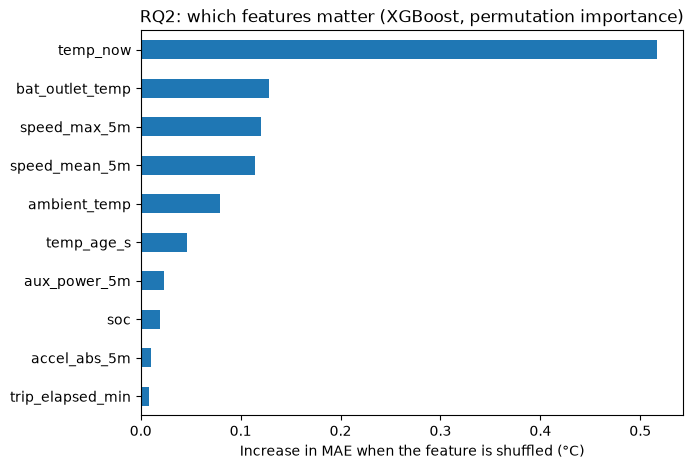

In [49]:
train, test = next(GroupKFold(n_splits=5).split(X_temp, y_change, temp_data["trip_id"]))
xgb_temp = temp_models["XGBoost"]().fit(X_temp.iloc[train], y_change.iloc[train])
importance = permutation_importance(xgb_temp, X_temp.iloc[test], y_change.iloc[test], n_repeats=5,
                                    scoring="neg_mean_absolute_error", random_state=0)
temp_importance = pd.Series(importance.importances_mean, index=TEMP_FEATURES).sort_values()

temp_importance.plot.barh(figsize=(7, 5), color="tab:blue")
plt.title("RQ2: which features matter (XGBoost, permutation importance)")
plt.xlabel("Increase in MAE when the feature is shuffled (°C)")
plt.show()

The current temperature matters most, followed by recent speed, coolant outlet temperature and outside temperature.

## 4.4 Hypothesis test
**H0:** the 5-minute temperature change does not depend on recent operating conditions.
**Test:** shuffle the (t, t + 5 min) pairs between rows of the same car, refit Ridge and record its MAE (1,000 times, since every shuffle needs a refit).

In [50]:
def refit_permutation_test(model, X, y, vehicles, groups, splitter, score, n_perm=1_000):
    observed = score(y, cross_validate({"m": model}, X, y, groups, splitter)["m"])
    null = []
    for _ in range(n_perm):
        y_shuffled = pd.Series(shuffle_within(y.to_numpy(), vehicles), index=y.index)
        null.append(score(y_shuffled, cross_validate({"m": model}, X, y_shuffled, groups, splitter)["m"]))
    return observed, np.array(null)

In [51]:
mae_rq2, null_rq2 = refit_permutation_test(temp_models["Ridge"], X_temp, y_change, temp_data["vehicle_id"].to_numpy(),
                                           temp_data["trip_id"], GroupKFold(n_splits=5), mean_absolute_error)
p_rq2 = (np.sum(null_rq2 <= mae_rq2) + 1) / (len(null_rq2) + 1)

print("Ridge MAE of the 5-min change (real data):", round(mae_rq2, 3), "°C")
print("Ridge MAE after shuffling (mean):", round(null_rq2.mean(), 3), "°C")
print("p-value:", round(p_rq2, 4))

Ridge MAE of the 5-min change (real data): 0.466 °C
Ridge MAE after shuffling (mean): 0.537 °C
p-value: 0.001


Ridge on the real data (MAE 0.466 °C) beats all 1,000 shuffles (mean MAE 0.54 °C), so p = 0.001 and we reject H0. This is the smallest p-value possible with 1,000 shuffles.

# Part 5: RQ3 - Rest-of-Trip Energy (Predictive Modeling) - Aditya M, Sumit
Can the first 5 minutes of a trip predict energy use for the rest of it?

## 5.1 Features
One row per trip, built only from the first 5 minutes and what is known at the start. The target is battery % per 100 km for the rest of the trip.

In [52]:
EARLY_S = 300

early = tel[tel["trip_id"].notna() & (tel["trip_elapsed_s"] < EARLY_S)].copy()
early["moving"] = early["speed"] > 2
g = early.groupby("trip_id")
early_features = pd.DataFrame({
    "early_speed_mean": g["speed"].mean(),
    "early_speed_std": g["speed"].std(),
    "early_speed_max": g["speed"].max(),
    "early_stop_fraction": 1 - g["moving"].mean(),
    "early_accel_abs": g["accel_ms2"].apply(lambda s: s.abs().mean()),
    "early_accel_p95": g["accel_ms2"].quantile(0.95),
    "early_dist_km": g["dist_km"].sum(),
    "early_ambient_temp": g["ambient_temp"].mean(),
    "early_aux_power": g["hv_aux_power"].mean(),
    "early_outlet_temp": g["bat_outlet_temp"].mean(),
    "soc_start": g["soc"].first(),
    "soc_at_5min": g["soc"].last(),
}).reset_index()

The target is battery % per 100 km after the first 5 minutes, plus the start time and car type.

In [53]:
rest = trips[["trip_id", "vehicle_id", "start_ts", "distance_km", "duration_min", "soc_end"]].merge(early_features, on="trip_id")
rest["early_soc_used"] = rest["soc_start"] - rest["soc_at_5min"]
rest["rest_km"] = rest["distance_km"] - rest["early_dist_km"]
rest["rest_soc_per_100km"] = 100 * (rest["soc_at_5min"] - rest["soc_end"]) / rest["rest_km"]
rest["start_hour"] = rest["start_ts"].dt.hour
rest["month_sin"] = np.sin(2 * np.pi * rest["start_ts"].dt.month / 12)
rest["month_cos"] = np.cos(2 * np.pi * rest["start_ts"].dt.month / 12)
rest["is_id3"] = rest["vehicle_id"].str.startswith("ID").astype(int)

We keep trips longer than 10 minutes with at least 5 km left after the first 5 minutes.

In [54]:
ENERGY_FEATURES = ["early_speed_mean", "early_speed_std", "early_speed_max", "early_stop_fraction", "early_accel_abs",
                   "early_accel_p95", "early_dist_km", "early_ambient_temp", "early_aux_power", "early_outlet_temp",
                   "soc_start", "early_soc_used", "start_hour", "month_sin", "month_cos", "is_id3"]

energy_data = rest[(rest["duration_min"] > 10) & (rest["rest_km"] >= 5)
                   & rest["rest_soc_per_100km"].between(5, 100)].reset_index(drop=True)
print("Trips for the rest-of-trip model:", len(energy_data), "| vehicles:", energy_data["vehicle_id"].nunique())

Trips for the rest-of-trip model: 1131 | vehicles: 7


## 5.2 Models
Lasso is a linear model that drops unhelpful features, and Random Forest captures non-linear effects. The baseline predicts the average of the training trips, and all models use the same 5-fold cross-validation.

In [55]:
X_energy = energy_data[ENERGY_FEATURES]
y_energy = energy_data["rest_soc_per_100km"]

energy_models = {
    "Baseline: training mean": lambda: DummyRegressor(strategy="mean"),
    "Lasso": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LassoCV(cv=5, random_state=0)),
    "Random Forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                                                 n_jobs=-1, random_state=0)),
}

energy_pred = cross_validate(energy_models, X_energy, y_energy, None, KFold(n_splits=5, shuffle=True, random_state=0))

energy_results = pd.DataFrame({name: regression_scores(y_energy, p) for name, p in energy_pred.items()}).T
energy_results.round(3)

,MAE,RMSE,R2
Baseline: training mean,5.968,7.691,-0.002
Lasso,5.024,6.654,0.250
Random Forest,4.775,6.443,0.297


Random Forest has the lowest error (MAE 4.78 vs 5.97 SOC % per 100 km for the baseline, 20% lower, R² = 0.30). Lasso is close (MAE 5.02, R² = 0.25), so a linear model already captures most of the gain.

## 5.3 Feature importance

In [56]:
lasso = energy_models["Lasso"]().fit(X_energy, y_energy)
lasso_coef = pd.Series(lasso[-1].coef_, index=ENERGY_FEATURES)

In [57]:
train, test = next(KFold(n_splits=5, shuffle=True, random_state=0).split(X_energy))
rf_energy = energy_models["Random Forest"]().fit(X_energy.iloc[train], y_energy.iloc[train])
importance = permutation_importance(rf_energy, X_energy.iloc[test], y_energy.iloc[test], n_repeats=20,
                                    scoring="neg_mean_absolute_error", random_state=0)
energy_importance = pd.Series(importance.importances_mean, index=ENERGY_FEATURES)

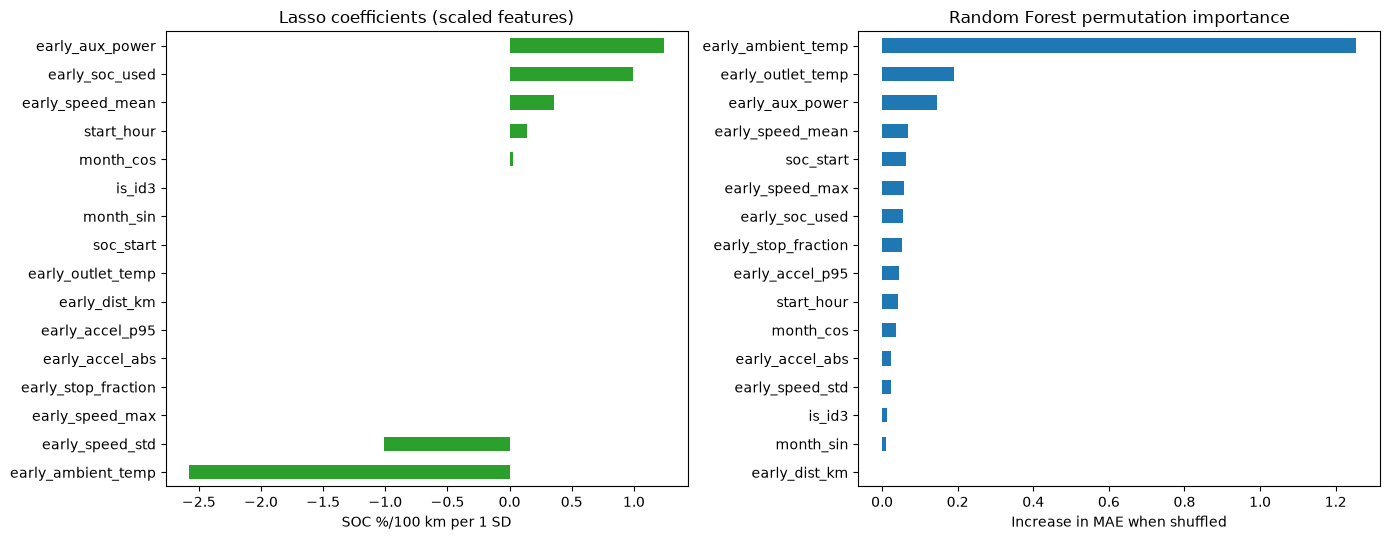

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
lasso_coef.sort_values().plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("Lasso coefficients (scaled features)")
axes[0].set_xlabel("SOC %/100 km per 1 SD")
energy_importance.sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Random Forest permutation importance")
axes[1].set_xlabel("Increase in MAE when shuffled")
plt.tight_layout()
plt.show()

Lasso keeps only 7 of the 16 features. Both models rank outside temperature and heater/AC power highly: colder starts and more heating mean more energy for the rest of the trip.

## 5.4 Hypothesis test
**H0:** rest-of-trip energy use does not depend on early-trip driving.
**Test:** shuffle the rest-of-trip energy between trips of the same car, refit Lasso and record its R² (1,000 times).

In [59]:
r2_rq3, null_rq3 = refit_permutation_test(energy_models["Lasso"], X_energy, y_energy, energy_data["vehicle_id"].to_numpy(),
                                          None, KFold(n_splits=5, shuffle=True, random_state=0), r2_score)
p_rq3 = (np.sum(null_rq3 >= r2_rq3) + 1) / (len(null_rq3) + 1)

print("Lasso R² (real data):", round(r2_rq3, 3))
print("Lasso R² after shuffling (max):", round(null_rq3.max(), 3))
print("p-value:", round(p_rq3, 4))

Lasso R² (real data): 0.25
Lasso R² after shuffling (max): 0.032
p-value: 0.001


Lasso reaches R² = 0.25 on the real data, while no shuffle gets above 0.03, so p = 0.001 and we reject H0.

# Part 6: Summary

| RQ | Result | Hypothesis test |
| --- | --- | --- |
| RQ1: driving regimes | 4 K-Means regimes (silhouette 0.27 vs 0.13 for speed bins) | After removing temperature, energy use differs by regime (p = 0.0003) |
| RQ2: battery temperature in 5 min | XGBoost MAE 0.32 °C, 42% better than persistence | Recent operating conditions improve the forecast (p = 0.001) |
| RQ3: rest-of-trip energy | Random Forest MAE 4.78, 20% better than the mean (R² = 0.30) | Early-trip driving predicts the rest of the trip (p = 0.001) |

All three tests stay significant after a Bonferroni correction (0.05 / 3 = 0.017).

**Next steps**
- Tune hyperparameters with nested cross-validation
- RQ4: thermal-demand classifier, reusing the RQ2 features
- RQ5: decide whether to add the battery-health dataset